# Exploratory Data Analysis

**Goal:** Understand the data and identify patterns useful for predicting whether a session ends with a purchase.

In [1]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.preprocessing import load_data

sns.set_style("whitegrid")

In [2]:
df = load_data()
print(f"Shape: {df.shape}")
df.head()

Shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


## 1. Dataset Overview

In [3]:
print("DataTypes:")
print(df.dtypes)

print("\nNumber of missing Values:", df.isnull().sum().sum())
print(f"\nDuplicates: {df.duplicated().sum()}")

DataTypes:
Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                          str
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                    str
Weekend                       bool
Revenue                       bool
dtype: object

Number of missing Values: 0

Duplicates: 125


**Note:** 125 duplicate rows were found (~1% of the data). They will be removed during preprocessing.

## 2. Target Variable

The target is imbalanced. Accuracy alone will be misleading; F1 and ROC-AUC are more appropriate.

Revenue
False    10422
True      1908
Name: count, dtype: int64

In percentages:
Revenue
False    84.5
True     15.5
Name: proportion, dtype: float64


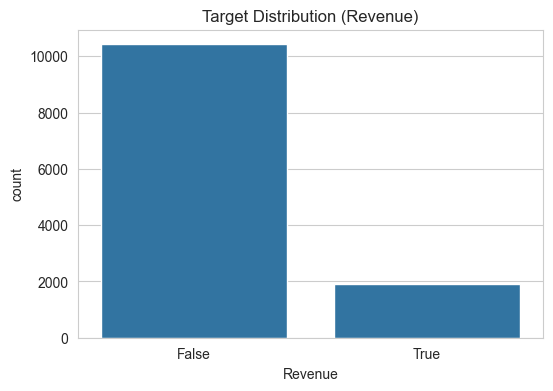

In [4]:
print(df["Revenue"].value_counts())
print("\nIn percentages:")
print(df["Revenue"].value_counts(normalize=True).round(3) * 100)

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Revenue")
plt.title("Target Distribution (Revenue)")
plt.show()

## 3. Numerical Features

In [5]:
num_cols = [
    "Administrative", "Administrative_Duration",
    "Informational", "Informational_Duration",
    "ProductRelated", "ProductRelated_Duration",
    "BounceRates", "ExitRates", "PageValues", "SpecialDay"
]

df[num_cols].describe().round(2)

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay
count,12330.00,12330.00,12330.00,12330.00,12330.00,12330.00,12330.00,12330.00,12330.00,12330.00
mean,2.32,80.82,0.50,34.47,31.73,1194.75,0.02,0.04,5.89,0.06
std,3.32,176.78,1.27,140.75,44.48,1913.67,0.05,0.05,18.57,0.20
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,0.00,0.00,0.00,0.00,7.00,184.14,0.00,0.01,0.00,0.00
50%,1.00,7.50,0.00,0.00,18.00,598.94,0.00,0.03,0.00,0.00
75%,4.00,93.26,0.00,0.00,38.00,1464.16,0.02,0.05,0.00,0.00
max,27.00,3398.75,24.00,2549.38,705.00,63973.52,0.20,0.20,361.76,1.00


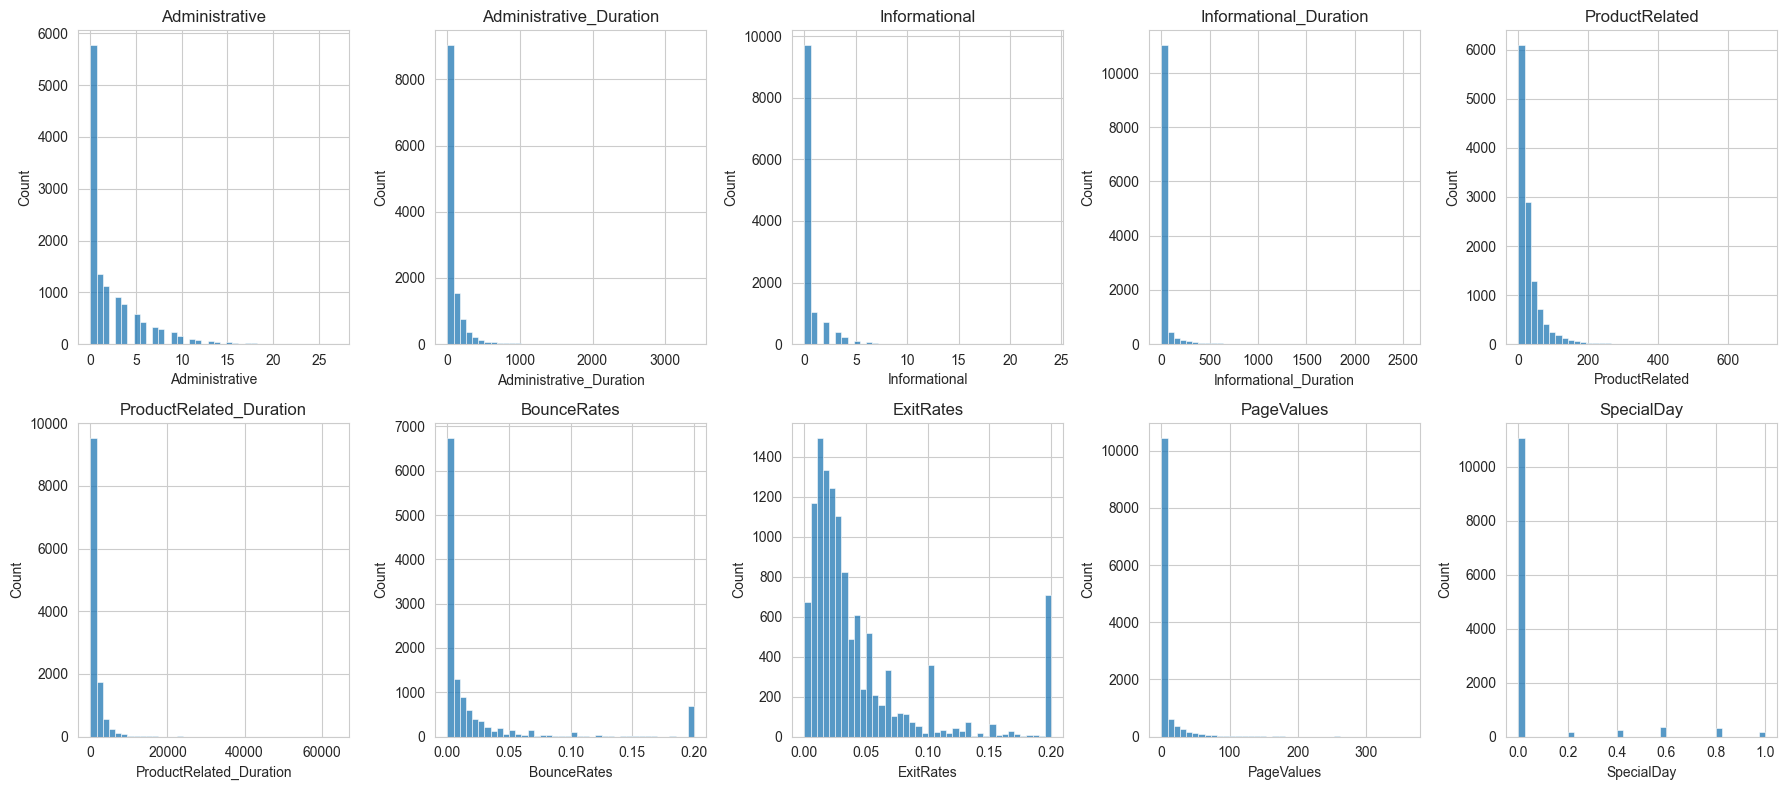

In [6]:
fig, axes = plt.subplots(2, 5, figsize=(18, 8))
axes = axes.ravel()

for i, col in enumerate(num_cols):
    sns.histplot(df[col], bins=40, ax=axes[i])
    axes[i].set_title(col)

plt.tight_layout()
plt.show()

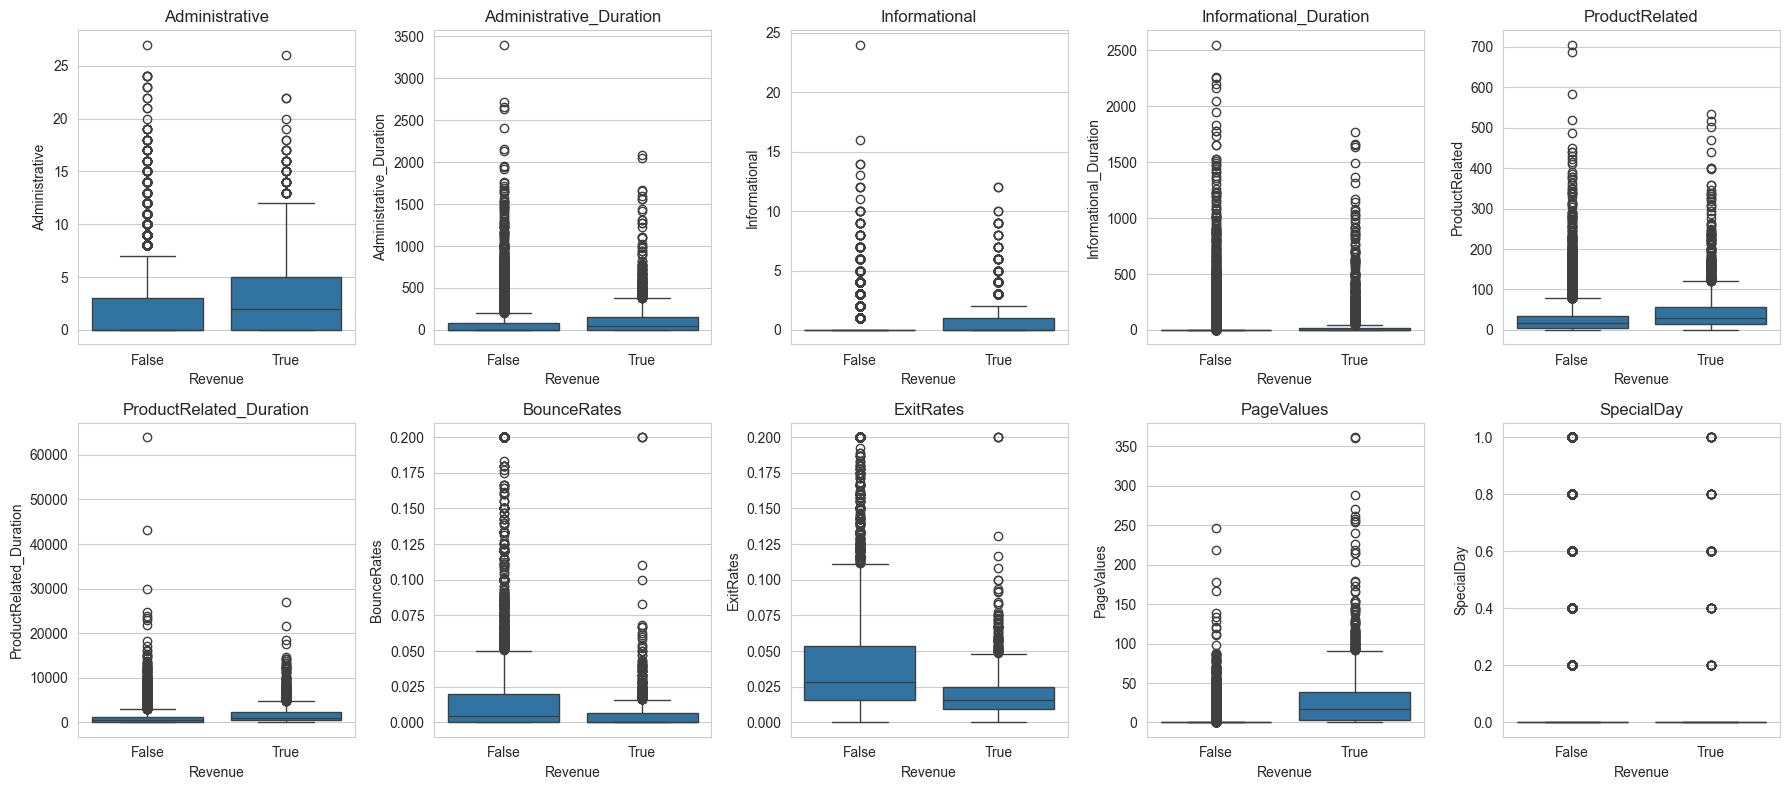

In [7]:
fig, axes = plt.subplots(2, 5, figsize=(18, 8))
axes = axes.ravel()

for i, col in enumerate(num_cols):
    sns.boxplot(data=df, x="Revenue", y=col, ax=axes[i])
    axes[i].set_title(col)

plt.tight_layout()
plt.show()

## 4. Categorical Features

`OperatingSystems`, `Browser`, `Region` and `TrafficType` are encoded as integers.  
The original dataset does not provide the mapping of these codes.

In [8]:
cat_cols = [
    "Month", "OperatingSystems", "Browser", "Region",
    "TrafficType", "VisitorType", "Weekend"
]

for col in cat_cols:
    print(f"\n=== {col} ===")
    print(df[col].value_counts())


=== Month ===
Month
May     3364
Nov     2998
Mar     1907
Dec     1727
Oct      549
Sep      448
Aug      433
Jul      432
June     288
Feb      184
Name: count, dtype: int64

=== OperatingSystems ===
OperatingSystems
2    6601
1    2585
3    2555
4     478
8      79
6      19
7       7
5       6
Name: count, dtype: int64

=== Browser ===
Browser
2     7961
1     2462
4      736
5      467
6      174
10     163
8      135
3      105
13      61
7       49
12      10
11       6
9        1
Name: count, dtype: int64

=== Region ===
Region
1    4780
3    2403
4    1182
2    1136
6     805
7     761
9     511
8     434
5     318
Name: count, dtype: int64

=== TrafficType ===
TrafficType
2     3913
1     2451
3     2052
4     1069
13     738
10     450
6      444
8      343
5      260
11     247
20     198
9       42
7       40
15      38
19      17
14      13
18      10
16       3
12       1
17       1
Name: count, dtype: int64

=== VisitorType ===
VisitorType
Returning_Visitor    10551
Ne

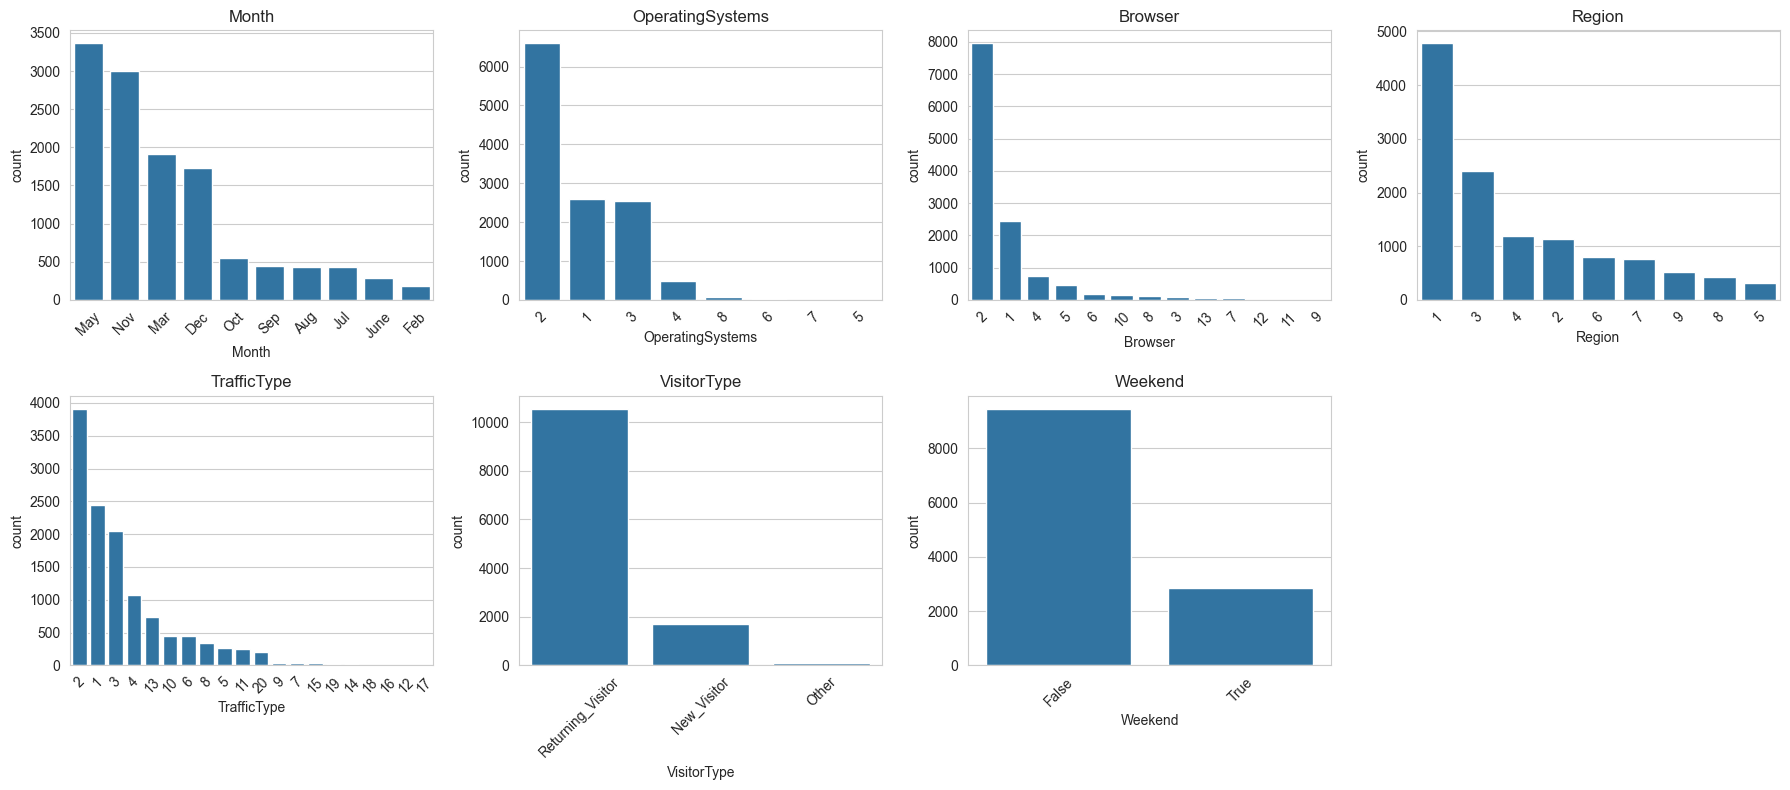

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.ravel()

for i, col in enumerate(cat_cols):
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order, ax=axes[i])
    axes[i].set_title(col)
    axes[i].tick_params(axis="x", rotation=45)

axes[-1].set_visible(False)
plt.tight_layout()
plt.show()

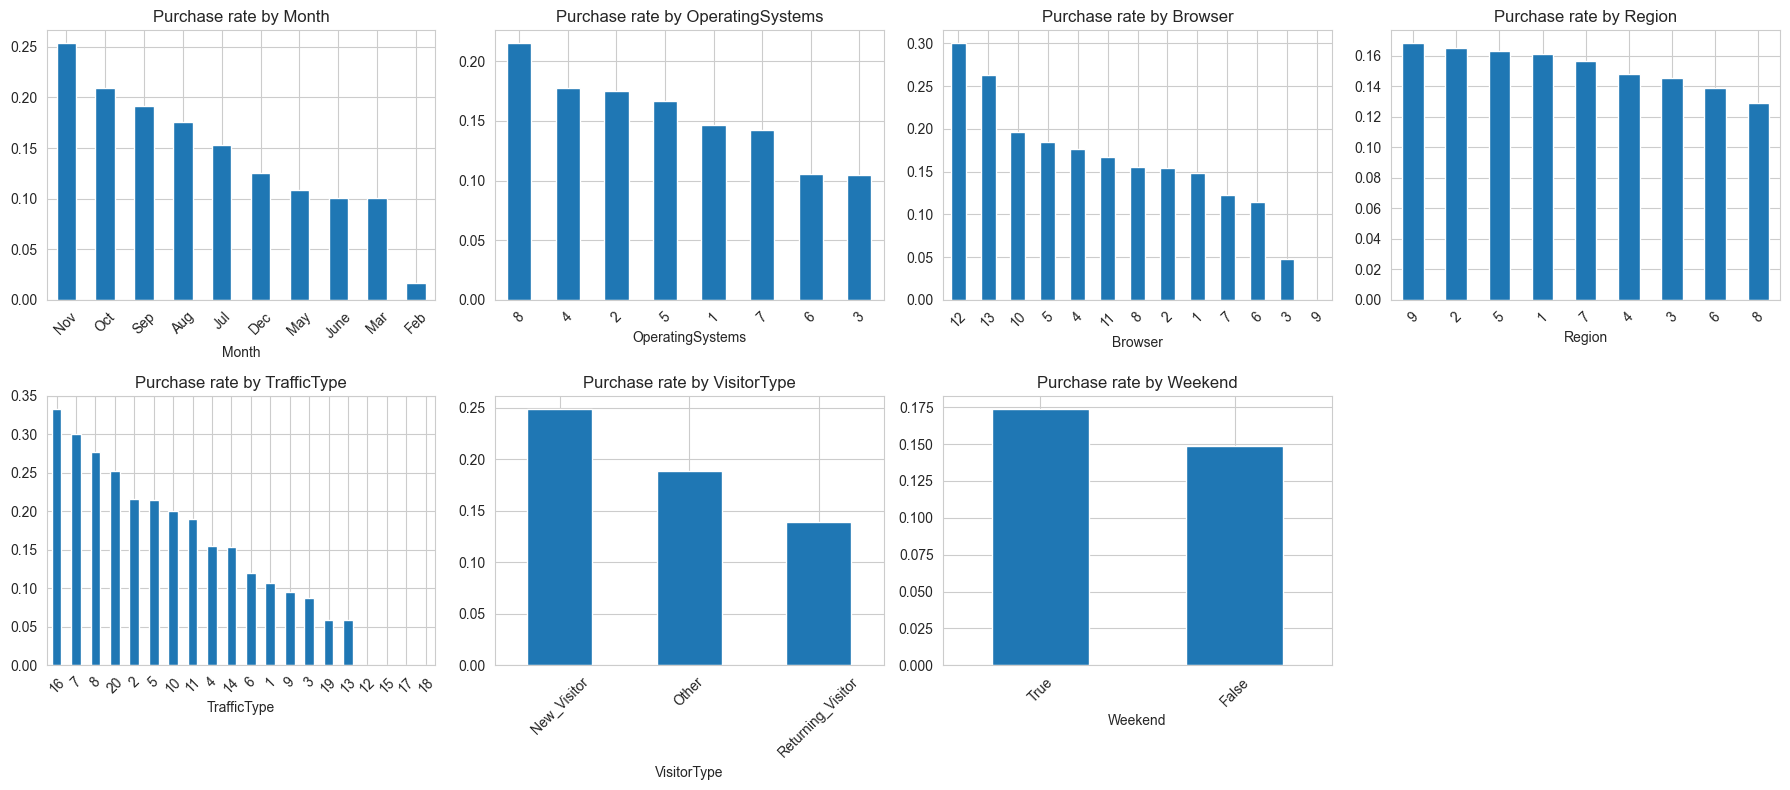

In [10]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.ravel()

for i, col in enumerate(cat_cols):
    rate = df.groupby(col)["Revenue"].mean().sort_values(ascending=False)
    rate.plot(kind="bar", ax=axes[i])
    axes[i].set_title(f"Purchase rate by {col}")
    axes[i].tick_params(axis="x", rotation=45)

axes[-1].set_visible(False)
plt.tight_layout()
plt.show()

## 5. Correlation with Target

Revenue                    1.000
PageValues                 0.493
ExitRates                  0.207
ProductRelated             0.159
ProductRelated_Duration    0.152
BounceRates                0.151
Administrative             0.139
Informational              0.095
Administrative_Duration    0.094
SpecialDay                 0.082
Informational_Duration     0.070
Name: Revenue, dtype: float64


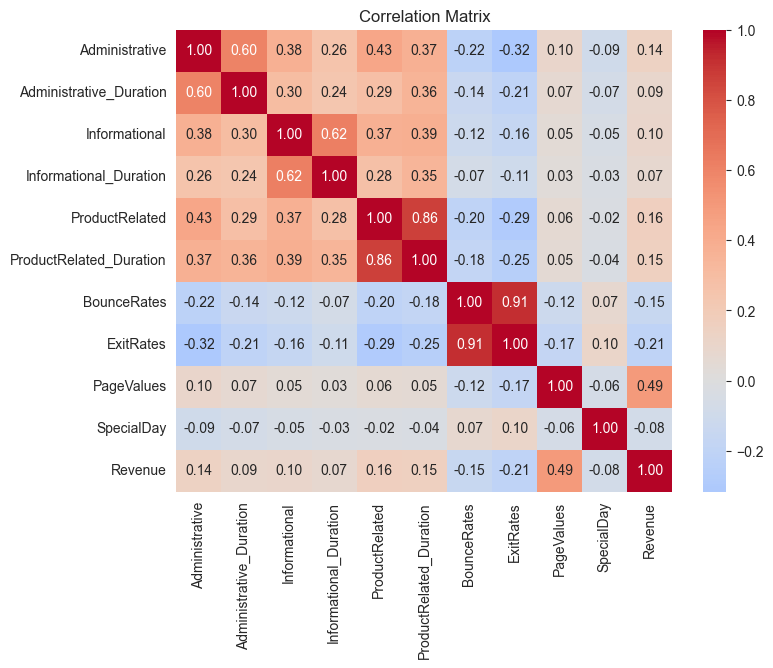

In [11]:
corr = df[num_cols + ["Revenue"]].corr()["Revenue"].abs().sort_values(ascending=False)
print(corr.round(3))

plt.figure(figsize=(8, 6))
sns.heatmap(
    df[num_cols + ["Revenue"]].corr(),
    annot=True, fmt=".2f", cmap="coolwarm", center=0
)
plt.title("Correlation Matrix")
plt.show()

## 6. Key Findings

- Target is imbalanced (~15.5% positive class). Prefer F1, ROC-AUC and PR-AUC over accuracy.
- 125 duplicate rows were found and will be removed.
- `PageValues` shows the strongest relationship with the target.
- `BounceRates` and `ExitRates` are higher for non-purchasing sessions.
- Duration and page-count features are right-skewed.
- `Month` and `VisitorType` show noticeable differences in purchase rate.
- Exact mappings for `OperatingSystems`, `Browser`, `Region` and `TrafficType` are not available.
- No missing values.